# Human Plasma aggregation

Read the source protocol CSVs for one condition and write its compact, deduplicated union.

In [1]:
CONDITION="human_plasma"
WRITE_EXPORTS=True
NOTEBOOK_ID="aggregation_human_plasma"
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "src/pep_compass").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.protocols.half_life.filtering import load_half_life_data, prepare_protocol, export_protocol
from proteolysis_data_manager.integration.half_life.schema import CLEAN_COLUMNS, source_mask, row_key, typed
from proteolysis_data_manager.analysis.half_life.visualization import (formatted_table, duration_summary, plot_duration_distributions,
    plot_acceptance_conditions, plot_before_after, readable_time_axis, time_bins, DURATION_COLORS, DURATION_LABELS)
DATA_ROOT = ROOT / "data/half_time_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_half_life"
RESULTS = SERIES.parents[1] / "results/0_data_analysis_half_life" / CONDITION / NOTEBOOK_ID
if WRITE_EXPORTS: RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False, "axes.grid":True, "grid.alpha":.12})
def table(frame):
    if len(frame)>30: display(HTML(f"<p>Preview: 30 of {len(frame)} rows.</p>"))
    display(HTML(formatted_table(frame, limit=30)))
def figure(fig, name):
    if WRITE_EXPORTS: fig.savefig(RESULTS / name, bbox_inches="tight")
    plt.show(); plt.close(fig)
def counts(frame):
    point=frame.half_life_seconds.notna()
    return {"observations":len(frame), "sequences":frame.sequence.nunique(), "numeric":int(point.sum()),
            "class_only":int((~point & frame.half_life_class.notna()).sum()),
            "unresolved":int((~point & frame.half_life_class.isna()).sum())}

from proteolysis_data_manager.integration.half_life.aggregation import aggregate_environment, source_accounting
SOURCES=["peplife2","plifepred","dramp","pepmsnd","cavaco"]


## Inputs and verified measurement identity

Central manifests verify input CSVs and their shared normalization/protocol policy. A shared source reference plus identical scientific fields establishes a repeated normalized measurement. Equal sequences or equal half-lives alone do not. Missing fields were already enriched during normalization, and the complete source/ID lists survive final aggregation.

No wide provenance columns or report files are added. Conflicting measurements remain separate; their explanations are in `normalized/remarks_<source>.md`.

In [2]:
if not WRITE_EXPORTS:
    raise RuntimeError("Template export disabled. Copy into a condition folder and enable WRITE_EXPORTS.")
before, after, lineage, possible, manifest = aggregate_environment(DATA_ROOT, CONDITION, SOURCES)
table(pd.DataFrame(manifest["inputs"]))
table(pd.DataFrame([{"condition":CONDITION,"source_input_rows":len(before),"final_measurements":len(after),"repeated_input_rows_merged":len(before)-len(after),**counts(after),"reported_ci95":int(after.ci_level.eq(.95).sum()),"unconfirmed_coincident_points":len(possible)}]))

source,csv,sha256,source_rows
peplife2,processed/human_plasma/sources/peplife2.csv,9ed7c001cb56030c6b772f37bda56bbf3c93104c48bb256087b84142a82f2226,184
plifepred,processed/human_plasma/sources/plifepred.csv,c79da69559651ecf318ad2426c53f675657994d716603022b20e0df6e1163d3d,16
dramp,processed/human_plasma/sources/dramp.csv,bcfdb8e3f5b9d745ef218bfb704164a34ef2f29b4c0e383a8e070719d23b7bd8,5
pepmsnd,processed/human_plasma/sources/pepmsnd.csv,f969817902ea567c652b4a6750c3374f1aebdb3824ab31370754b093dc0d00b4,148
cavaco,processed/human_plasma/sources/cavaco.csv,b39517b0258e9a3f155c4ebf118e0596d59db411d7597c180568f80c0f645b11,0


condition,source_input_rows,final_measurements,repeated_input_rows_merged,observations,sequences,numeric,class_only,unresolved,reported_ci95,unconfirmed_coincident_points
human_plasma,353,342,11,342,221,276,22,44,0,47


## Source coverage, label availability and PEPlife2 overlap

Raw source representations and normalized measurements have different denominators: normalization merges verified repeated source rows. The next reduction selects species/matrix and the explicit assay mode, then applies pH/temperature gates. Tables account for each reduction.

Every retained row belongs to one label group: numerical, class-only, or unresolved. Missing half-life does not remove it. Shared sequences and verified shared measurements with PEPlife2 are reported separately; sequence overlap is not deduplication evidence.

coverage


source,raw_source_representations,normalized_measurements,condition_records,selected_assay_mode,other_known_mode,unknown_assay_mode,outside_ph_temperature,exported_source_records
peplife2,4500,4366,438,184,254,0,0,184
plifepred,424,261,31,16,15,0,0,16
dramp,111,111,8,5,0,3,0,5
pepmsnd,635,635,231,148,83,0,0,148
cavaco,16,16,0,0,0,0,0,0


label_types


source,exported_records,numeric,class_only,unresolved,without_numeric_half_life
peplife2,184,122,22,40,62
plifepred,16,16,0,0,0
dramp,5,1,0,4,4
pepmsnd,148,148,0,0,0
cavaco,0,0,0,0,0


peplife2_overlap


source,comparison,shared_sequences,shared_sequence_records,verified_same_measurements,new_sequences
peplife2,reference,110,184,None,0
plifepred,against PEPlife2,16,16,11,0
dramp,against PEPlife2,1,5,0,0
pepmsnd,against PEPlife2,21,21,0,111
cavaco,against PEPlife2,0,0,0,0


source,parameter,cavaco,dramp,peplife2,pepmsnd,plifepred
,ci_level,0,5,184,148,16
,ci_lower_seconds,0,5,184,148,16
,ci_upper_seconds,0,5,184,148,16
,half_life_class,0,4,40,0,0
,half_life_seconds,0,4,62,0,0
,matrix_fraction,0,5,184,148,16
,peptide_concentration_um,0,5,103,148,11
,ph,0,5,178,148,16
,replicate_count,0,5,184,148,16
,sd_seconds,0,5,184,148,16


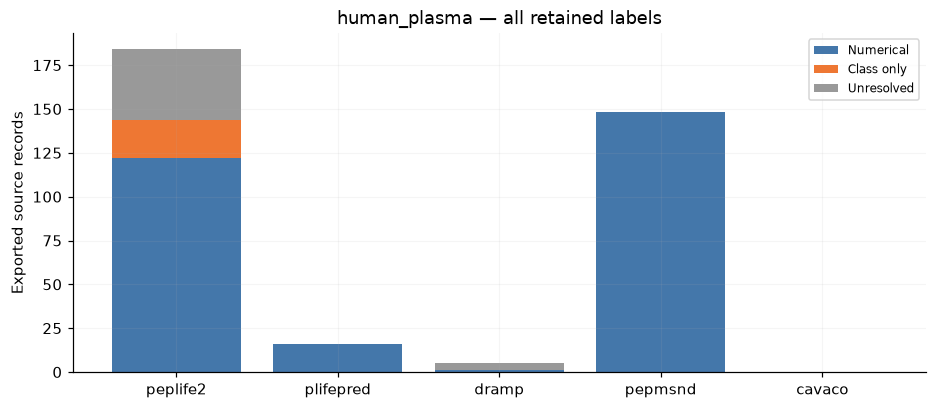

In [3]:
inventory=load_half_life_data(DATA_ROOT)
accounting=source_accounting(DATA_ROOT,inventory,before,after,manifest["configuration"],SOURCES)
for name in ["coverage","label_types","peplife2_overlap"]:
    print(name); table(accounting[name])
table(accounting["missingness"].pivot(index="parameter",columns="source",values="missing").reset_index())
labels=accounting["label_types"].set_index("source")
fig,ax=plt.subplots(figsize=(10,4)); bottom=pd.Series(0,index=labels.index)
for field,color,label in [("numeric","#4477AA","Numerical"),("class_only","#EE7733","Class only"),("unresolved","#999999","Unresolved")]:
    ax.bar(labels.index,labels[field],bottom=bottom,color=color,label=label);bottom+=labels[field]
ax.set(ylabel="Exported source records",title=CONDITION+" — all retained labels");ax.legend(fontsize=8)
figure(fig,"source_label_availability.png")
for _,r in accounting["label_types"].iterrows():
    assert r.numeric+r.class_only+r.unresolved==r.exported_records
for _,r in accounting["coverage"].iterrows():
    assert r.condition_records==r.selected_assay_mode+r.other_known_mode+r.unknown_assay_mode
    assert r.selected_assay_mode==r.outside_ph_temperature+r.exported_source_records

## Duration classes, distributions and missingness

**short** <30 min (blue); **medium** 30 min–6 h inclusive (orange); **long** >6 h (green); unresolved (gray). All numerical and class-only observations enter class counts. Numerical histograms use reported points or the explicitly documented CI-midpoint exception only.

Before/after counts here describe merging source copies of shared observations, not filtering out class-only data.

duration_class,time_interval,all_assigned_records,exact_point_records,bounded_or_non_numeric_records,stage
unresolved,no unique interval,44,0,44,Source CSV inputs
short,<30 min,129,127,2,Source CSV inputs
medium,30 min–6 h,80,79,1,Source CSV inputs
long,>6 h,100,81,19,Source CSV inputs
unresolved,no unique interval,44,0,44,Deduplicated union
short,<30 min,123,121,2,Deduplicated union
medium,30 min–6 h,79,78,1,Deduplicated union
long,>6 h,96,77,19,Deduplicated union


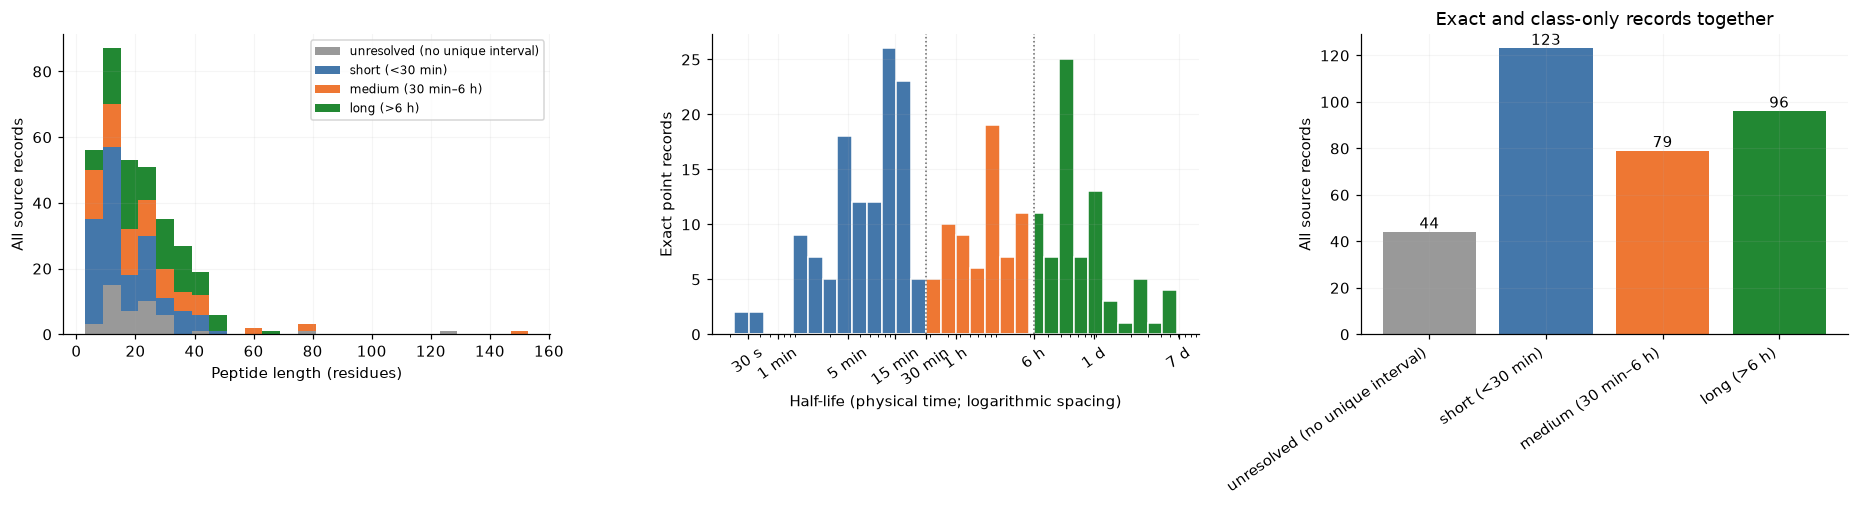

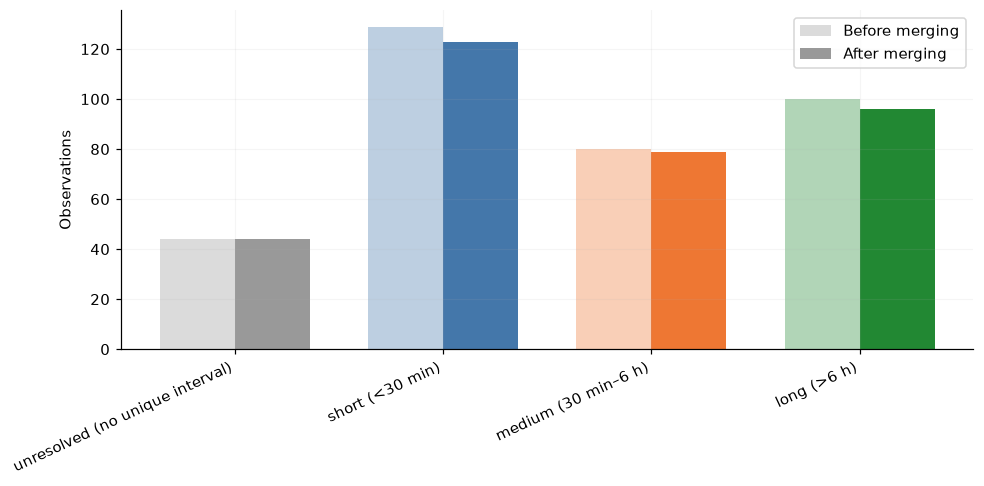

field,missing,denominator
sequence,0,342
sequence_length,0,342
chirality,148,342
topology,0,342
n_terminal_modification,0,342
c_terminal_modification,0,342
other_modifications,0,342
species,0,342
matrix,0,342
matrix_fraction,342,342


normalized_row_key,source,id
2d97c8baf407a69c452b1c5b37e383861c5a792be147f40b585a0ca426c86eb1,peplife2,all:1049
bb2ef0cd3ebdc042ba25afc4b5ec2765a8f50c78ede26804bb7df84beae767ba,peplife2,all:1050
c189698b6d12f4240b4a1f1473da4b4bb1993deb268a6dc8453a5a7db4ae53e3,dramp,stability:DRAMP29854
dc0260adc87de5b9f69bf47aca9cb5b79b901652c0d944f94d8b1f80640437aa,peplife2,all:1051
3e1af226f5e9e79c9443d15744e8640fadcf86e8c1acdd514a9989b99d784244,peplife2,all:1052
ff55ad0fc9ee5d03d3d16ed04303c159e0de2c51bdd930c3c4a0113cf20f02c9,peplife2,all:1053
f0e34228763726d1f4892fd6fb85e6db02038737650b4879e5d0c87312ab3b95,dramp,stability:DRAMP29857
58ebf09a95c9c55c40b632c72e6d5741bee719c6bb273cd9984d337656b11790,peplife2,all:1054
3f75858268208e4872678e06a53dc1b0117feb4375089bd0ed8f0fe964c480ae,dramp,stability:DRAMP29858
29d268bc2fac305965ab814dd6ff640f71d00ef337fab8682f1c7eb8a3dd46c2,peplife2,all:1055


source,source_record_id,sequence,sequence_length,chirality,topology,n_terminal_modification,c_terminal_modification,other_modifications,species,matrix,matrix_fraction,temperature_c,ph,peptide_concentration_um,half_life_seconds,sd_seconds,ci_lower_seconds,ci_upper_seconds,ci_level,replicate_count,half_life_class,in_vivo_in_vitro
[peplife2],"[{'id': 'all:1049', 'source': 'peplife2'}]",AAGIGILTV,9,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,1,22,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1071', 'source': 'peplife2'}]",HAEGTFTSDVSSYLEGQAAKEFIAWLVKGR,30,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,<NA>,2.232e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
[peplife2],"[{'id': 'all:1106', 'source': 'peplife2'}]",HAEGTFTSDVSSYLEGQAAKEFIAWLVKGR,30,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,2000,2.232e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
[peplife2],"[{'id': 'all:1108', 'source': 'peplife2'}]",YAEGTFISDYSIAMDKIHQQDFVNWLLAQKGKKNDWKHNITQ,42,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,2000,2.16e+04,<NA>,<NA>,<NA>,<NA>,<NA>,medium,in vitro
"[peplife2, plifepred]","[{'id': 'all:1777', 'source': 'peplife2'}, {'id': 'mixed:1777', 'source': 'plifepred'}, {'id': 'natural:1777', 'source': 'plifepred'}]",SLRRSSCFGGRIDRIGAQSGCNSFRY,26,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,<NA>,144,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:2246', 'source': 'peplife2'}]",YGGFL,5,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,<NA>,1026,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:2247', 'source': 'peplife2'}]",YGGFL,5,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,<NA>,1026,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:2249', 'source': 'peplife2'}]",YGGFL,5,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,<NA>,726,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:2254', 'source': 'peplife2'}]",YGGFL,5,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,<NA>,726,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:2250', 'source': 'peplife2'}]",YGGFL,5,l,linear,free,free,free,human,plasma,<NA>,<NA>,<NA>,<NA>,714,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro


In [4]:
table(pd.concat([duration_summary(before).assign(stage="Source CSV inputs"),duration_summary(after).assign(stage="Deduplicated union")],ignore_index=True))
figure(plot_duration_distributions(after),"final_distributions.png")
summary_before=duration_summary(before);summary_after=duration_summary(after);x=np.arange(len(summary_after))
fig,ax=plt.subplots(figsize=(10,4))
colors=[DURATION_COLORS[c] for c in summary_after.duration_class]
ax.bar(x-.18,summary_before.all_assigned_records,width=.36,color=colors,alpha=.35,label="Before merging")
ax.bar(x+.18,summary_after.all_assigned_records,width=.36,color=colors,label="After merging")
ax.set_xticks(x,[DURATION_LABELS[c] for c in summary_after.duration_class],rotation=25,ha="right");ax.set(ylabel="Observations");ax.legend()
figure(fig,"before_after_classes.png")
table(pd.DataFrame([{"field":f,"missing":int(after[f].isna().sum()),"denominator":len(after)} for f in CLEAN_COLUMNS if f not in ["source","source_record_id"]]))
table(lineage);table(possible)
assert not after.apply(row_key,axis=1).duplicated().any()

## Final common CSV

The result uses the same 23 fields as normalization and source protocols. Select `half_life_seconds.notna()` for numerical analysis; select `half_life_seconds.isna() & half_life_class.notna()` for class-only validation. Both can use the duration class. Unresolved labels remain present with null values. Missing SD and CI stay null.

`source` is a list of all contributing bases; `source_record_id` is the full list of source-qualified references. In CSV these two fields are JSON; the library reader decodes them.

TODO (later analysis): estimate validation tolerances separately without changing reported CI.

In [5]:
table(pd.DataFrame({"column":CLEAN_COLUMNS}))
print("Final CSV:",DATA_ROOT/"processed"/CONDITION/(CONDITION+".csv"))

column
source
source_record_id
sequence
sequence_length
chirality
topology
n_terminal_modification
c_terminal_modification
other_modifications
species


Final CSV: /Users/max/Documents/repositories/pep-compass/data/half_time_datasets/processed/human_plasma/human_plasma.csv
